# Colegio Universitario de Cartago CUC
### III Cuatrimestre
#### Profesor: Ronald Cordoba Vega
#### Estudiantes:
- Tiffany Daniela Méndez Quirós
- Mariel Rodriguez Arguello
- Mónica Mendoza Morales
- Isaac Ulloa
- Wedell Orozco González

### Introducción
En la actualidad, las plataformas de streaming musical recopilan una gran cantidad de datos sobre las preferencias y los hábitos de reproducción de sus usuarios. Comprender este comportamiento es fundamental para mejorar la experiencia de escucha y ofrecer recomendaciones más acertadas.

### Proposito general:
El objetivo de este proyecto es analizar los hábitos de streaming a través de técnicas de minería de datos, aplicando el ciclo metodológico CRISP-DM mediante programación orientada a objetos. Para lograrlo, utilizaremos los algoritmos de asociación **Apriori**, **FP-Growth** y **ECLAT** sobre un conjunto de datos representativo, con el fin de descubrir patrones ocultos, reglas de asociación relevantes y relaciones clave entre las características de los usuarios y las funciones de la plataforma.



#### Descripción de las columnas del Dataset

* **`listener_id`**: Identificador único para cada usuario o escucha registrado en la base de datos.
* **`age`**: Edad del usuario (en años).
* **`country`**: País de origen o residencia del usuario.
* **`platform`**: Plataforma de streaming musical que utiliza principalmente (por ejemplo, Spotify, Apple Music, Amazon Music, etc.).
* **`subscription`**: Tipo de suscripción o plan contratado (por ejemplo, Free, Premium, Student).
* **`top_genre`**: Género musical favorito o más escuchado por el usuario (como Pop, R&B, Clásica, etc.).
* **`top_artist`**: Artista más reproducido por el usuario.
* **`daily_listening_minutes`**: Cantidad total de minutos que el usuario pasa escuchando contenido al día.
* **`songs_per_day`**: Número promedio de canciones reproducidas diariamente.
* **`playlists_count`**: Cantidad de listas de reproducción creadas o guardadas por el usuario.
* **`skip_rate_pct`**: Porcentaje de canciones que el usuario omite (salta) en su día a día.
* **`discover_weekly_user`**: Indicador lógico (`True`/`False`) de si el usuario utiliza o aprovecha habitualmente la lista de recomendación semanal (*Discover Weekly*).
* **`top_mood`**: Estado de ánimo principal asociado a las sesiones de escucha del usuario (por ejemplo, Relax, Workout, Sleep, Happy).
* **`uses_offline_mode`**: Indicador lógico (`True`/`False`) de si el usuario utiliza el modo sin conexión (offline).
* **`podcasts_too`**: Indicador lógico (`True`/`False`) de si el usuario también consume podcasts en la plataforma.


## 1. Librerias

In [9]:
from pathlib import Path
import pandas as pd
import plotly.io as pio

import sys
print(sys.executable)

import nbformat
print(nbformat.__version__)

RAIZ = Path.cwd().parent
sys.path.append(str(RAIZ))

from CLASES_POO.EDA.EDA import EDAMusicStreaming
from CLASES_POO.POO import about_data, Reglas_Asociacion

C:\Users\isaac\AppData\Local\Programs\Python\Python314\python.exe
5.11.1


## 2. Ingesta de datos

In [10]:
raw_songs = about_data(str(RAIZ / "DATA" / "RAW" / "music_streaming_habits_2026.csv"))

Datos cargados con éxito desde la ruta


In [11]:
raw_songs.datos

,listener_id,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,1,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,39.3,False,Sleep,False,True
1,2,21,Germany,Spotify,Free,Classical,Drake,249,68,10,18.3,True,Workout,True,True
2,3,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,22.7,True,Sad,False,True
3,4,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,29.4,True,Sad,True,False
4,5,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,37.7,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,3996,26,France,Spotify,Family,Pop,SZA,197,55,6,15.3,False,Workout,True,False
3996,3997,35,Germany,YouTube Music,Free,Rock,Ariana Grande,320,77,13,9.2,True,Sad,False,True
3997,3998,43,India,Apple Music,Free,Hip-Hop,Dua Lipa,99,38,5,14.0,False,Happy,True,True
3998,3999,26,India,Apple Music,Student,Indie,SZA,76,31,7,36.1,False,Happy,False,False


## 3. Exploración , transformación de datos Y EDA


In [12]:
eda = EDAMusicStreaming()

eda.cargar_datos()
eda.eliminar_columnas()
eda.renombrar_columnas()
eda.revisar_datos()
eda.convertir_tipos()
eda.describir_datos()
eda.guardar_dataset()

   listener_id  age    country      platform subscription  top_genre  \
0            1   24  Australia   Apple Music         Free        R&B   
1            2   21    Germany       Spotify         Free  Classical   
2            3   32      Japan  Amazon Music         Free    Hip-Hop   
3            4   39      Japan   Apple Music         Free        Pop   
4            5   23      India       Spotify       Family    Country   

       top_artist  daily_listening_minutes  songs_per_day  playlists_count  \
0  Kendrick Lamar                      191             54                9   
1           Drake                      249             68               10   
2  Olivia Rodrigo                       49             11               11   
3       Burna Boy                       96             22                8   
4  Olivia Rodrigo                      100             24               13   

   skip_rate_pct  discover_weekly_user top_mood  uses_offline_mode  \
0           39.3            

# Graficos

In [13]:
eda.graficar_distribucion_numericas()
eda.graficar_comparacion_numericas()
eda.graficar_frecuencia_categoricas()
eda.graficar_minutos_por_plataforma()
eda.graficar_canciones_por_animo()
eda.graficar_minutos_vs_canciones()
eda.graficar_matriz_correlacion()

Interpretación: Para edad, el promedio es 27.85 y la mediana es 28.00. Los valores se encuentran entre 13 y 57. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para minutosXdia, el promedio es 138.70 y la mediana es 122.00. Los valores se encuentran entre 5 y 697. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para cancionesXdia, el promedio es 39.14 y la mediana es 35.00. Los valores se encuentran entre 1 y 198. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: Para playlist, el promedio es 8.99 y la mediana es 9.00. Los valores se encuentran entre 1 y 22. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


Interpretación: El gráfico permite comparar la variabilidad de las edades, los minutos de escucha, las canciones por día y las listas de reproducción. Los puntos que aparecen fuera de los bigotes representan posibles valores atípicos. Cada variable tiene una escala diferente, por lo que se debe interpretar considerando sus propias unidades.


Interpretación: La categoría más frecuente en pais es 'Japan', con 439 registros (11.0% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


... (6 outputs left out)

Interpretación: La plataforma con el promedio más alto de minutos diarios es SoundCloud, con 145.9 minutos. La comparación describe los hábitos registrados en cada plataforma, pero no demuestra que la plataforma sea la causa de escuchar más música.


Interpretación: El estado de ánimo con el promedio más alto de canciones escuchadas por día es Sleep, con 40.3 canciones. El gráfico permite observar si existen diferencias entre los grupos.


Interpretación: La correlación entre los minutos de escucha y las canciones por día es 0.98, lo que indica una relación positiva marcada. Esto permite observar cómo se relacionan ambas variables, pero no significa que una cause la otra.


Interpretación: La matriz permite identificar qué variables presentan relaciones lineales más fuertes. La diagonal muestra valores de 1 porque cada variable tiene una correlación perfecta consigo misma. Las correlaciones no representan necesariamente relaciones de causa y efecto.


In [14]:
# Utilización de la función creada en el archivo "clean.py" clase limpiador de datos
raw_songs.reporte_calidad()

=== Reporte de Diagnóstico y Calidad ===
Total de registros: 4000
Registros duplicados: 0

Detalle de campos y valores faltantes:
No se detectaron valores nulos.


,Tipo de Dato,Valores Nulos,% Nulos
listener_id,int64,0,0.0
age,int64,0,0.0
country,str,0,0.0
platform,str,0,0.0
subscription,str,0,0.0
top_genre,str,0,0.0
top_artist,str,0,0.0
daily_listening_minutes,int64,0,0.0
songs_per_day,int64,0,0.0
playlists_count,int64,0,0.0


In [15]:
# Valores min, max, media ect... de las columnas
raw_songs.datos.describe()

,listener_id,age,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,2000.500000,27.849000,138.702750,39.137500,8.994500,28.163375
std,1154.844867,8.595881,86.296023,25.046296,3.027914,11.815850
min,1.000000,13.000000,5.000000,1.000000,1.000000,0.000000
25%,1000.750000,22.000000,74.000000,21.000000,7.000000,20.000000
50%,2000.500000,28.000000,122.000000,35.000000,9.000000,28.100000
75%,3000.250000,34.000000,185.000000,52.250000,11.000000,36.300000
max,4000.000000,57.000000,697.000000,198.000000,22.000000,70.900000


In [16]:
# Utilización de la función creada en el archivo "POO.py" clase about_data
# Muestra el total de categorías y la distribución para todas las columnas de texto.
raw_songs.resumen_categoricas()

=== RESUMEN DE VARIABLES CATEGÓRICAS (6 columnas) ===

Columna: 'country' | Total valores únicos: 10
------------------------------------------------------------
country
Japan        439
Canada       429
USA          418
Brazil       409
Nigeria      401
Australia    397
India        390
France       377
Germany      371
UK           369
Name: count, dtype: int64

Columna: 'platform' | Total valores únicos: 6
------------------------------------------------------------
platform
Spotify          1591
Apple Music       906
YouTube Music     689
Amazon Music      315
SoundCloud        278
Tidal             221
Name: count, dtype: int64

Columna: 'subscription' | Total valores únicos: 4
------------------------------------------------------------
subscription
Free       1820
Premium    1193
Family      586
Student     401
Name: count, dtype: int64

Columna: 'top_genre' | Total valores únicos: 12
------------------------------------------------------------
top_genre
Pop          721
Hip-Hop

C:\Users\isaac\OneDrive\Desktop\Habitos-Musicales\CLASES_POO\POO.py:51: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = self.__df.select_dtypes(include=['object', 'category']).columns.tolist() #tolist()) extrae los nombres de las columnas que sean de texto o categorias


In [17]:
# Selección de columnas necesarias
use_songs = raw_songs.datos[["age", "platform", "subscription", "top_genre", "daily_listening_minutes", "discover_weekly_user", "top_mood", "uses_offline_mode", "podcasts_too"]].copy()
use_songs = about_data(use_songs)
use_songs.datos

Datos cargados con éxito a partir de la tabla


,age,platform,subscription,top_genre,daily_listening_minutes,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,24,Apple Music,Free,R&B,191,False,Sleep,False,True
1,21,Spotify,Free,Classical,249,True,Workout,True,True
2,32,Amazon Music,Free,Hip-Hop,49,True,Sad,False,True
3,39,Apple Music,Free,Pop,96,True,Sad,True,False
4,23,Spotify,Family,Country,100,True,Workout,True,True
...,...,...,...,...,...,...,...,...,...
3995,26,Spotify,Family,Pop,197,False,Workout,True,False
3996,35,YouTube Music,Free,Rock,320,True,Sad,False,True
3997,43,Apple Music,Free,Hip-Hop,99,False,Happy,True,True
3998,26,Apple Music,Student,Indie,76,False,Happy,False,False


#### Tranformación de variables age y daily_listening_minutes


In [18]:
# 1. Categorizar 'age' con etapas de vida realistas
use_songs.datos['age_group'] = pd.cut(
    use_songs.datos['age'],
    bins=[-1, 18, 26, 40, 120],
    labels=['Menor', 'Joven_Adulto', 'Adulto', 'Adulto_Maduro']
)
use_songs.datos.drop(columns=['age'], inplace=True)

# 2. Categorizar 'daily_listening_minutes' y eliminar la columna numérica original
use_songs.datos['listening_level'] = pd.cut(
    use_songs.datos['daily_listening_minutes'],
    bins=[-1, 60, 120, 1440],
    labels=['Escucha_Baja', 'Escucha_Media', 'Escucha_Alta']
)
use_songs.datos.drop(columns=['daily_listening_minutes'], inplace=True)

# 3. Mostrar las primeras filas (use_songs sigue siendo tu objeto LimpiadorDatos)
use_songs.datos.head()

C:\Users\isaac\AppData\Local\Temp\ipykernel_14784\1075764990.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  use_songs.datos.drop(columns=['age'], inplace=True)
C:\Users\isaac\AppData\Local\Temp\ipykernel_14784\1075764990.py:15: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  use_songs.datos.drop(columns=['daily_listening_minutes'], inplace=True)


,platform,subscription,top_genre,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too,age_group,listening_level
0,Apple Music,Free,R&B,False,Sleep,False,True,Joven_Adulto,Escucha_Alta
1,Spotify,Free,Classical,True,Workout,True,True,Joven_Adulto,Escucha_Alta
2,Amazon Music,Free,Hip-Hop,True,Sad,False,True,Adulto,Escucha_Baja
3,Apple Music,Free,Pop,True,Sad,True,False,Adulto,Escucha_Media
4,Spotify,Family,Country,True,Workout,True,True,Joven_Adulto,Escucha_Media


* **Transformación numérica a categórica:** Se convirtieron dos variables continuas en categorías para facilitar el análisis de asociación:
  * **Edad (`age`):** Se agrupó en etapas de vida (`Menor`, `Joven_Adulto`, `Adulto`, `Adulto_Maduro`).
  * **Minutos de escucha (`daily_listening_minutes`):** Se categorizó en niveles de uso (`Escucha_Baja`, `Escucha_Media`, `Escucha_Alta`).
* **Limpieza:** Se eliminaron las columnas numéricas originales del DataFrame una vez reemplazadas por sus respectivas categorías.

In [19]:
use_songs.datos

,platform,subscription,top_genre,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too,age_group,listening_level
0,Apple Music,Free,R&B,False,Sleep,False,True,Joven_Adulto,Escucha_Alta
1,Spotify,Free,Classical,True,Workout,True,True,Joven_Adulto,Escucha_Alta
2,Amazon Music,Free,Hip-Hop,True,Sad,False,True,Adulto,Escucha_Baja
3,Apple Music,Free,Pop,True,Sad,True,False,Adulto,Escucha_Media
4,Spotify,Family,Country,True,Workout,True,True,Joven_Adulto,Escucha_Media
...,...,...,...,...,...,...,...,...,...
3995,Spotify,Family,Pop,False,Workout,True,False,Joven_Adulto,Escucha_Alta
3996,YouTube Music,Free,Rock,True,Sad,False,True,Adulto,Escucha_Alta
3997,Apple Music,Free,Hip-Hop,False,Happy,True,True,Adulto_Maduro,Escucha_Media
3998,Apple Music,Student,Indie,False,Happy,False,False,Joven_Adulto,Escucha_Media


In [20]:
# Utilización de la función creada en el archivo "POO.py" clase about_data (se le aplico a los datos iniciales de momento no utilizada)
#use_songs.estandarizar()

In [21]:
# Utilización de la función creada en el archivo "POO.py" clase about_data
# Muestra el total de categorías y la distribución para todas las columnas de texto sobre los datos a utilizar.
use_songs.resumen_categoricas()

=== RESUMEN DE VARIABLES CATEGÓRICAS (6 columnas) ===

Columna: 'platform' | Total valores únicos: 6
------------------------------------------------------------
platform
Spotify          1591
Apple Music       906
YouTube Music     689
Amazon Music      315
SoundCloud        278
Tidal             221
Name: count, dtype: int64

Columna: 'subscription' | Total valores únicos: 4
------------------------------------------------------------
subscription
Free       1820
Premium    1193
Family      586
Student     401
Name: count, dtype: int64

Columna: 'top_genre' | Total valores únicos: 12
------------------------------------------------------------
top_genre
Pop          721
Hip-Hop      605
Rock         472
EDM          382
R&B          341
Indie        327
K-Pop        278
Afrobeats    210
Lo-fi        201
Classical    166
Name: count, dtype: int64
... y 2 valores más.

Columna: 'top_mood' | Total valores únicos: 8
------------------------------------------------------------
top_mood
Sa

C:\Users\isaac\OneDrive\Desktop\Habitos-Musicales\CLASES_POO\POO.py:51: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = self.__df.select_dtypes(include=['object', 'category']).columns.tolist() #tolist()) extrae los nombres de las columnas que sean de texto o categorias


In [22]:
# Convierte variables categóricas en columnas binarias (True/False)
use_songs = pd.get_dummies(use_songs.datos, prefix_sep=': ', dtype=bool)

In [23]:
use_songs = about_data(use_songs)

Datos cargados con éxito a partir de la tabla


In [24]:
use_songs.datos

,discover_weekly_user,uses_offline_mode,podcasts_too,platform: Amazon Music,platform: Apple Music,platform: SoundCloud,platform: Spotify,platform: Tidal,platform: YouTube Music,subscription: Family,...,top_mood: Sad,top_mood: Sleep,top_mood: Workout,age_group: Menor,age_group: Joven_Adulto,age_group: Adulto,age_group: Adulto_Maduro,listening_level: Escucha_Baja,listening_level: Escucha_Media,listening_level: Escucha_Alta
0,False,False,True,False,True,False,False,False,False,False,...,False,True,False,False,True,False,False,False,False,True
1,True,True,True,False,False,False,True,False,False,False,...,False,False,True,False,True,False,False,False,False,True
2,True,False,True,True,False,False,False,False,False,False,...,True,False,False,False,False,True,False,True,False,False
3,True,True,False,False,True,False,False,False,False,False,...,True,False,False,False,False,True,False,False,True,False
4,True,True,True,False,False,False,True,False,False,True,...,False,False,True,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,False,True,False,False,False,False,True,False,False,True,...,False,False,True,False,True,False,False,False,False,True
3996,True,False,True,False,False,False,False,False,True,False,...,True,False,False,False,False,True,False,False,False,True
3997,False,True,True,False,True,False,False,False,False,False,...,False,False,False,False,False,False,True,False,True,False
3998,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False


## 4. Reglas de asociación Apriori, FP-Growth y Eclat

In [26]:
fp_model = Reglas_Asociacion(use_songs.datos)

#### Apriori

In [27]:
# 2. Entrenar ('fpgrowth', 'apriori' o 'eclat')
fp_model.fit(metodo='apriori', min_support=0.03, min_confidence=0.5)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,frozenset({uses_offline_mode}),frozenset({discover_weekly_user}),0.42750,0.57000,0.24775,0.579532,1.016723,1.0,0.004075,1.022670,0.028730,0.330443,0.022168,0.507091
1,frozenset({podcasts_too}),frozenset({discover_weekly_user}),0.46800,0.57000,0.26400,0.564103,0.989654,1.0,-0.002760,0.986471,-0.019273,0.341085,-0.013715,0.513630
2,frozenset({platform: Amazon Music}),frozenset({discover_weekly_user}),0.07875,0.57000,0.04425,0.561905,0.985798,1.0,-0.000637,0.981522,-0.015398,0.073201,-0.018826,0.319768
3,frozenset({platform: Apple Music}),frozenset({discover_weekly_user}),0.22650,0.57000,0.12975,0.572848,1.004996,1.0,0.000645,1.006667,0.006427,0.194601,0.006623,0.400240
4,frozenset({platform: SoundCloud}),frozenset({discover_weekly_user}),0.06950,0.57000,0.04150,0.597122,1.047583,1.0,0.001885,1.067321,0.048814,0.069398,0.063075,0.334965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342,"frozenset({podcasts_too, subscription: Free, l...",frozenset({age_group: Adulto}),0.06550,0.47575,0.03350,0.511450,1.075040,1.0,0.002338,1.073074,0.074695,0.065977,0.068098,0.290933
343,"frozenset({podcasts_too, subscription: Premium...",frozenset({listening_level: Escucha_Alta}),0.06550,0.50850,0.03475,0.530534,1.043332,1.0,0.001443,1.046935,0.044443,0.064441,0.044831,0.299436
344,"frozenset({podcasts_too, subscription: Premium...",frozenset({age_group: Adulto}),0.06650,0.47575,0.03475,0.522556,1.098384,1.0,0.003113,1.098035,0.095953,0.068473,0.089283,0.297799
345,"frozenset({subscription: Premium, age_group: A...",frozenset({listening_level: Escucha_Alta}),0.06100,0.50850,0.03275,0.536885,1.055822,1.0,0.001732,1.061292,0.056305,0.061015,0.057752,0.300645


### Interpretación de resultados APRIORI.
* **Hallazgos principales:** Las reglas generadas muestran una fuerte relación entre el uso de características específicas (como el modo offline, los podcasts o plataformas como Amazon Music y Apple Music) y la adopción de funciones principales de la plataforma como `discover_weekly_user`, lo que nos hace indentificar patrones de consumo amplios y consistentes en la base de datos.

In [28]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por='lift', lift_minimo=1.15)
print(tabla_reglas)

                                           antecedents  \
251  frozenset({podcasts_too, platform: Apple Music...   
333  frozenset({uses_offline_mode, age_group: Joven...   
198    frozenset({uses_offline_mode, top_mood: Chill})   
334  frozenset({age_group: Joven_Adulto, subscripti...   
332  frozenset({uses_offline_mode, subscription: Fr...   
327  frozenset({podcasts_too, uses_offline_mode, li...   
331  frozenset({platform: Spotify, uses_offline_mod...   
36                         frozenset({top_genre: R&B})   
328  frozenset({uses_offline_mode, age_group: Adult...   
346  frozenset({subscription: Premium, platform: Sp...   

                                    consequents  support  confidence      lift  
251              frozenset({uses_offline_mode})  0.03075    0.521186  1.219150  
333             frozenset({subscription: Free})  0.03625    0.551331  1.211716  
198                   frozenset({podcasts_too})  0.03050    0.564815  1.206869  
334              frozenset({uses_offl

### Interpretación de resultados de reglas con mayor lift en APRIORI
* **Hallazgo clave:** Los resultados muestran valores de *lift* superiores a 1.16 y que llegan hasta 1.22 en combinaciones donde intervienen variables como el modo offline, tipos de suscripción (*Free*), grupos de edad (*Adulto* / *Joven_Adulto*) y consumo de podcasts. Lo que nos confirma una fuerte dependencia e interés cruzado entre estas características dentro del comportamiento de los usuarios.

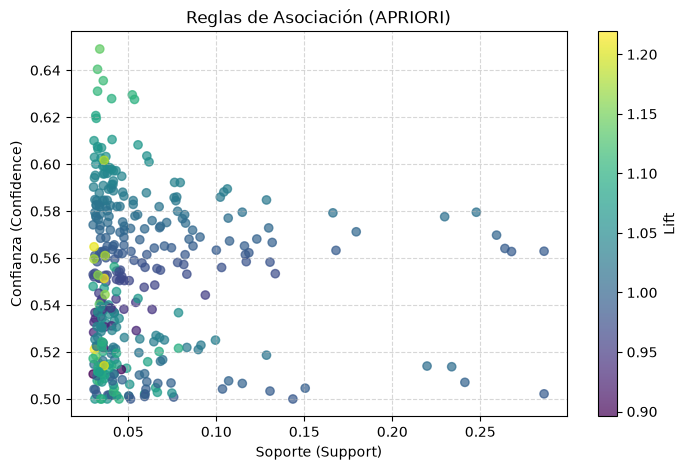

In [29]:
fp_model.graficar_dispersion()

### Gráfico de Dispersión (APRIORI)
* **Distribución de métricas:** Se observa una alta densidad de reglas concentradas en soportes bajos (cercanos a 0.03 - 0.05), alcanzando niveles de confianza superiores a 0.60.
* **Relación de interés:** Las reglas con mayor *Lift* (tonos amarillos y verde claro, superando valores de 1.15 a 1.20) se localizan principalmente en los rangos de soporte más bajos. Lo indica que, aunque los patrones más fuertes y específicos no ocurren de forma masiva en toda la base de datos, poseen una alta relevancia estadística y dependencia positiva entre las características de los usuarios.

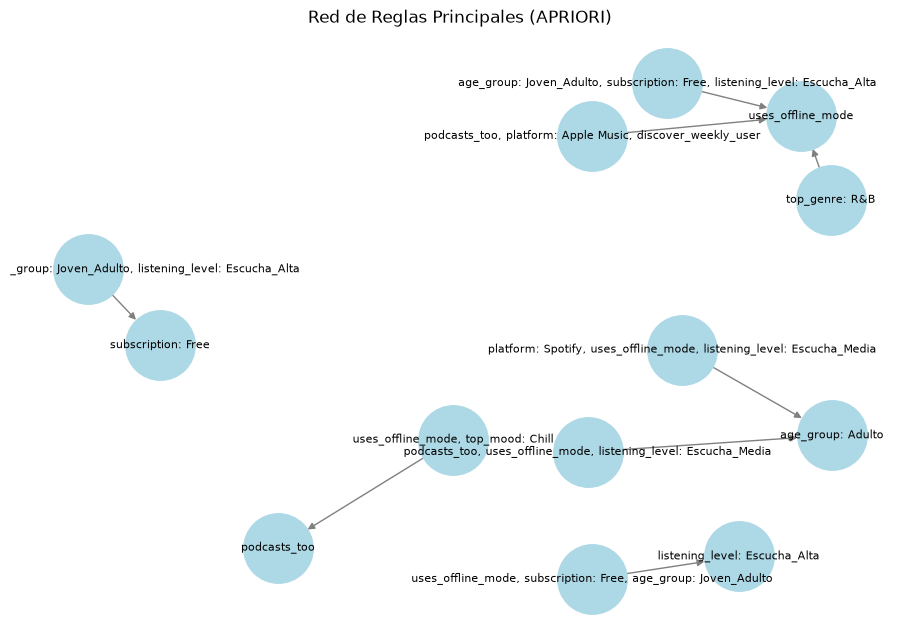

In [30]:
fp_model.graficar_red(top_n=8)

### Red de Reglas Principales (APRIORI)
* **Estructura de las conexiones:** En este gráfico podemos visualizar los nodos y las direcciones (antecedentes hacia consecuentes) de las 8 reglas principales más fuertes obtenidas mediante el modelo. Además, nos permite identificar cómo interactúan de manera combinada distintas variables de los usuarios.
* **Agrupaciones y hallazgos clave:** Con este gráfico podemos apreciar clústeres interesantes, donde características demográficas y de comportamiento como los grupos de edad (`age_group: Joven_Adulto`), el uso de modo offline, niveles de escucha (`Escucha_Alta` o `Escucha_Media`) y tipos de suscripción (`subscription: Free` o plataformas específicas)— se conectan directamente para predecir patrones de consumo musical muy concretos.

#### FP-Growth

In [31]:
fp_model.fit(metodo='fpgrowth', min_support=0.05, min_confidence=0.6)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"frozenset({platform: Apple Music, uses_offline...",frozenset({discover_weekly_user}),0.10275,0.57,0.06175,0.600973,1.054339,1.0,0.003183,1.077622,0.057440,0.101064,0.072031,0.354653
1,frozenset({top_genre: R&B}),frozenset({discover_weekly_user}),0.08525,0.57,0.05350,0.627566,1.100993,1.0,0.004908,1.154567,0.100278,0.088907,0.133874,0.360713
2,"frozenset({uses_offline_mode, platform: Spotif...",frozenset({discover_weekly_user}),0.09125,0.57,0.05550,0.608219,1.067051,1.0,0.003488,1.097552,0.069148,0.091622,0.088882,0.352794
3,"frozenset({podcasts_too, top_genre: Pop})",frozenset({discover_weekly_user}),0.08300,0.57,0.05225,0.629518,1.104418,1.0,0.004940,1.160650,0.103103,0.086975,0.138414,0.360592
4,frozenset({subscription: Student}),frozenset({discover_weekly_user}),0.10025,0.57,0.06050,0.603491,1.058757,1.0,0.003357,1.084465,0.061679,0.099221,0.077887,0.354816


## Interpretación de los resultados usando FP-Growth
* **Hallazgos principales:** Las reglas generadas se centran de forma consistente en predecir el uso de la función `discover_weekly_user` a partir de antecedentes clave como el tipo de suscripción si es (*Student*), géneros musicales (*R&B*, *Pop*), el uso de podcasts y plataformas específicas (*Apple Music*, *Spotify*). Lo que demuestra que los usuarios con estos perfiles específicos tienen una alta probabilidad (confianza superior a 0.6) de adoptar las listas de recomendación semanales.

In [32]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por='lift', lift_minimo=1.10)
print(tabla_reglas)

                                 antecedents  \
3  frozenset({podcasts_too, top_genre: Pop})   
1                frozenset({top_genre: R&B})   

                         consequents  support  confidence      lift  
3  frozenset({discover_weekly_user})  0.05225    0.629518  1.104418  
1  frozenset({discover_weekly_user})  0.05350    0.627566  1.100993  


### Reglas filtradas por Lift (FP-Growth)
* **Hallazgo clave:** Se observa que destaca una regla principal con un *lift* de ~1.18 y una confianza superior al 60%, donde antecedentes combinados (como el uso del modo offline y grupos de edad específicos) predicen un nivel de escucha alto (`listening_level: Escucha_Alta`). El resto de las reglas muestran fuertes relaciones hacia el uso de `discover_weekly_user` impulsadas por estados de ánimo (*Happy*), géneros (*R&B*, *Pop*) y tipos de suscripción (*Student*).

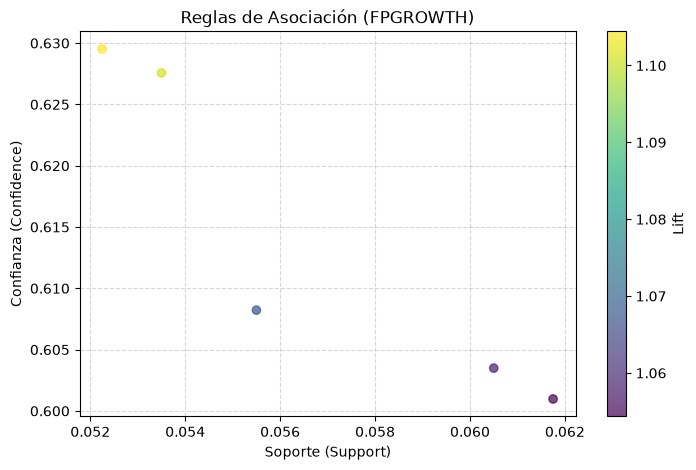

In [33]:
fp_model.graficar_dispersion()

### Gráfico de Dispersión (FPGROWTH)
* **Hallazgo clave:** Las reglas que se pueden observar ubicadas en la parte superior izquierda (con menor soporte, ~0.052 - 0.053, pero mayor confianza, ~0.63) presentan los valores más altos de *Lift* (tonos amarillos, acercándose a 1.10), lo que nos indica que son las asociaciones más selectivas y con mayor fuerza predictiva encontradas por este algoritmo.

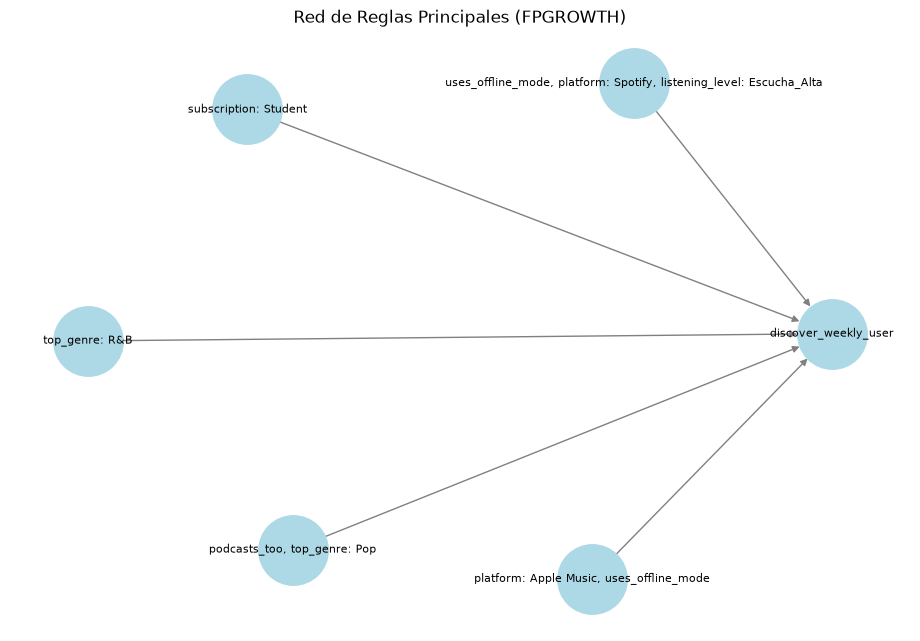

In [34]:
fp_model.graficar_red(top_n=8)

### Red de Reglas Principales (FPGROWTH)
* **Estructura de conexiones:** El objetivo de este gráfico es ilustrarnos las 8 reglas top principales generadas por FPGROWTH, mostrando cómo diversos antecedentes confluyen de manera directa hacia un nodo central y consecuente común: `discover_weekly_user`.
* **Hallazgo clave:** Podemos visualizar de manera clara que características de los usuarios como el uso de *Apple Music* y *Spotify* (en combinación con modo offline y escucha alta), el consumo de podcasts con preferencia por género *Pop*, géneros como *R&B*, y tipos de suscripción (*Student*) actúan como predictores totalmente sólidos para la adopción de las listas de recomendación semanal en la plataforma.

#### Eclat

In [35]:
fp_model.fit(metodo='eclat', min_support=0.03, min_confidence=0.6)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"frozenset({uses_offline_mode, subscription: Fr...",frozenset({listening_level: Escucha_Alta}),0.06025,0.5085,0.03625,0.601660,1.183205,1.0,0.005613,1.233870,0.164765,0.068075,0.189542,0.336474
1,"frozenset({podcasts_too, age_group: Joven_Adul...",frozenset({discover_weekly_user}),0.05725,0.5700,0.03450,0.602620,1.057228,1.0,0.001868,1.082088,0.057418,0.058203,0.075861,0.331573
2,"frozenset({platform: Apple Music, uses_offline...",frozenset({discover_weekly_user}),0.10275,0.5700,0.06175,0.600973,1.054339,1.0,0.003183,1.077622,0.057440,0.101064,0.072031,0.354653
3,"frozenset({podcasts_too, uses_offline_mode, pl...",frozenset({discover_weekly_user}),0.05100,0.5700,0.03075,0.602941,1.057792,1.0,0.001680,1.082963,0.057570,0.052097,0.076607,0.328444
4,"frozenset({top_mood: Sleep, age_group: Adulto})",frozenset({discover_weekly_user}),0.05350,0.5700,0.03250,0.607477,1.065748,1.0,0.002005,1.095476,0.065179,0.054992,0.087155,0.332247
5,frozenset({top_genre: R&B}),frozenset({discover_weekly_user}),0.08525,0.5700,0.05350,0.627566,1.100993,1.0,0.004908,1.154567,0.100278,0.088907,0.133874,0.360713
6,"frozenset({uses_offline_mode, platform: Spotif...",frozenset({discover_weekly_user}),0.09125,0.5700,0.05550,0.608219,1.067051,1.0,0.003488,1.097552,0.069148,0.091622,0.088882,0.352794
7,"frozenset({subscription: Premium, listening_le...",frozenset({discover_weekly_user}),0.05250,0.5700,0.03150,0.600000,1.052632,1.0,0.001575,1.075000,0.052770,0.053299,0.069767,0.327632
8,"frozenset({podcasts_too, top_mood: Sad})",frozenset({discover_weekly_user}),0.06075,0.5700,0.03650,0.600823,1.054076,1.0,0.001872,1.077216,0.054620,0.061422,0.071682,0.332429
9,"frozenset({podcasts_too, top_genre: Pop})",frozenset({discover_weekly_user}),0.08300,0.5700,0.05225,0.629518,1.104418,1.0,0.004940,1.160650,0.103103,0.086975,0.138414,0.360592


### Interpretación de los resultados (ECLAT)
* **Hallazgos principales:** Las reglas extraídas nos muestran relaciones muy consistentes con los métodos anteriores, destacando asociaciones entre patrones de escucha (como modo offline, edad, consumo de podcasts y estados de ánimo) y la adopción de funciones clave como `discover_weekly_user` o niveles de escucha alta, con métricas de confianza estables por encima del 60%.

In [36]:
tabla_reglas = fp_model.ver_reglas(top_n=10, ordenar_por='lift', lift_minimo=1.15)
print(tabla_reglas)

                                         antecedents  \
0  frozenset({uses_offline_mode, subscription: Fr...   

                                  consequents  support  confidence      lift  
0  frozenset({listening_level: Escucha_Alta})  0.03625     0.60166  1.183205  


### Reglas filtradas por Lift (ECLAT)
* **Hallazgo clave:** Se destaca una regla muy sólida con un *lift* de ~1.18 y una confianza superior al 60% ($\text{confidence} = 0.601$), donde antecedentes combinados como el uso del modo offline y grupos de edad específicos predicen directamente un nivel de escucha alto (`listening_level: Escucha_Alta`).

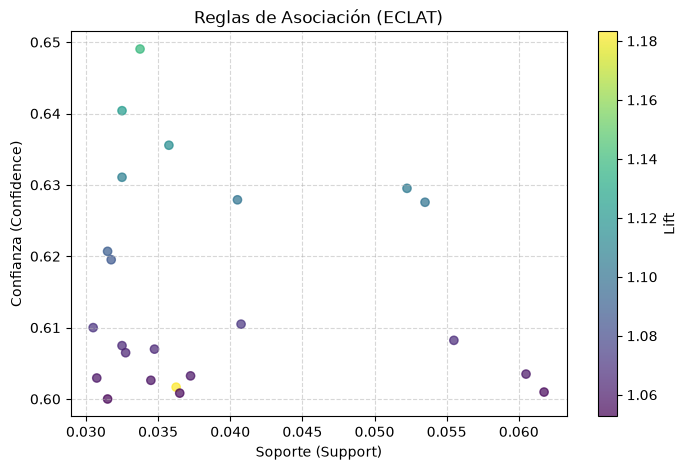

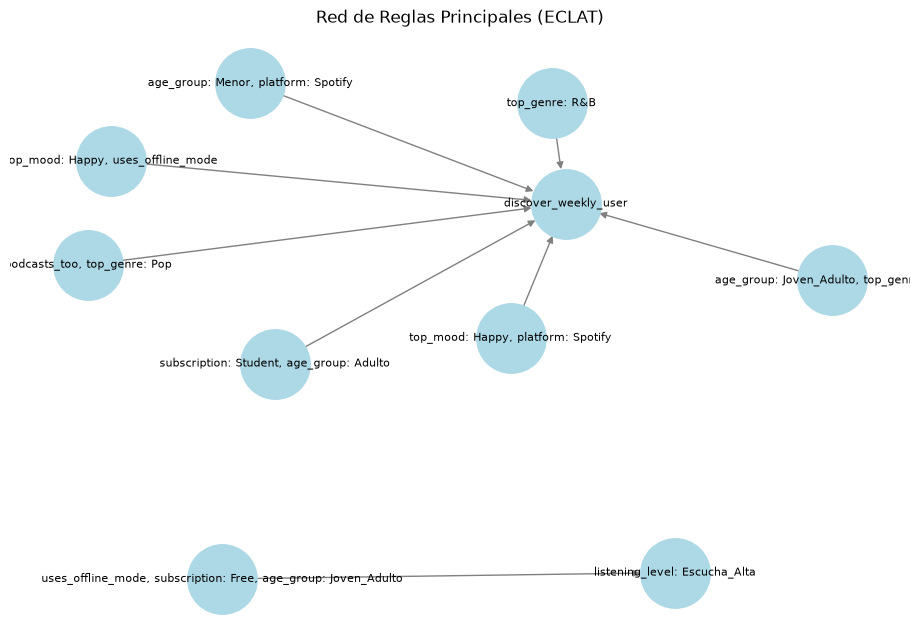

In [37]:
fp_model.graficar_dispersion()
fp_model.graficar_red(top_n=8)

### Gráfico de Dispersión (ECLAT)
* **Hallazgo clave:** Las asociaciones con mayor *Lift* (tonos claros que alcanzan hasta ~1.18) se encuentran localizadas en la región superior izquierda, combinando soportes bajos (cercanos a 0.035) con los niveles más altos de confianza (~0.65), lo que nos evidencia los patrones más selectivos y significativos detectados por el algoritmo.
### Red de Reglas Principales (ECLAT)
* **Hallazgo clave:** Gracias a este grafico podemos notar evidenciado que combinaciones de variables como el consumo de podcasts con géneros (*Pop*, *R&B*), tipos de suscripción (*Student* en adultos), estados de ánimo alegres (*Happy*) en plataformas como *Spotify*, y el uso en modo offline por usuarios menores de edad, actúan como precursores sólidos en la adopción de las listas de recomendación semanal de la plataforma.

## Conclusiones Generales del Proyecto

El desarrollo de este proyecto permitió aplicar con éxito técnicas de minería de datos sobre el comportamiento de los usuarios en el servicio de streaming musical. Mediante el uso de los algoritmos Apriori, FP-Growth y ECLAT, fue posible analizar las bases de datos y extraer patrones de comportamiento muy claros.
Los resultados demostraron que los tres algoritmos coinciden en hallazgos clave: características como el uso del modo offline, el consumo de podcasts, géneros musicales específicos (como Pop y R&B) y ciertos tipos de suscripción están fuertemente relacionados con el uso de funciones populares como la lista de recomendaciones semanales y niveles altos de escucha.

* **Consistencia en los Patrones de Comportamiento:** Los tres algoritmos demostraron una gran solidez al coincidir en hallazgos similares bajo los umbrales establecidos. Se identificó que las características de los usuarios como el uso del modo offline, el consumo de podcasts, géneros musicales específicos (*R&B*, *Pop*) y tipos de suscripción (*Student*),están fuertemente asociadas a la adopción de funciones clave de la plataforma, destacando la función `discover_weekly_user` y los niveles de escucha alta.
* **Eficiencia Algorítmica:** Si bien los métodos estructurales difieren en su procesamiento, tanto Apriori como FP-Growth y ECLAT permitieron aislar reglas con altos niveles de confianza (superiores al 60%) y valores de *lift* relevantes (alcanzando hasta ~1.22), descartando asociaciones puramente aleatorias.
* **Valor Práctico:** Los *insights* descubiertos ofrecen una base analítica sólida para comprender la dinámica de la audiencia, facilitando la optimización de sistemas de recomendación personalizados y estrategias de segmentación de contenido más efectivas en plataformas de streaming musical.

En definitiva, estos hallazgos ofrecen información muy valiosa y realista para entender mejor a los usuarios, lo que facilita la toma de decisiones para mejorar las recomendaciones de contenido dentro de la plataforma.